In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("wdi_clean.csv")

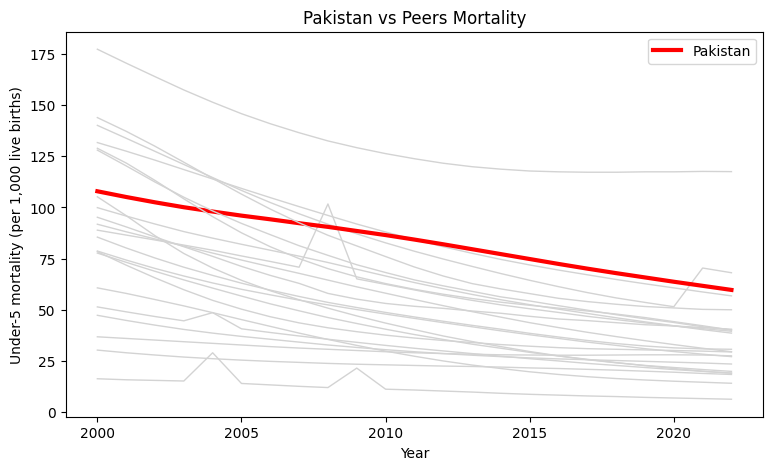

Year               2000   2022  change_pct
Country Name                              
Nigeria           177.3  117.5       -33.7
Ethiopia          140.1   68.1       -51.4
Pakistan          107.9   59.7       -44.7
Afghanistan       131.7   56.8       -56.9
Uganda            143.9   50.0       -65.3
Kenya              95.2   40.5       -57.5
Senegal           128.9   40.1       -68.9
Tanzania          128.0   40.1       -68.7
Myanmar            88.9   39.5       -55.6
Ghana              99.9   38.6       -61.4
Bangladesh         85.5   30.7       -64.1
India              91.8   29.5       -67.9
Tajikistan         78.4   29.4       -62.5
Philippines        36.8   27.5       -25.3
Nepal              78.7   27.1       -65.6
Egypt, Arab Rep.   47.3   23.5       -50.3
Cambodia          105.2   19.9       -81.1
Indonesia          51.4   19.1       -62.8
Bhutan             77.7   19.0       -75.5
Viet Nam           30.3   18.4       -39.3
Uzbekistan         60.7   14.1       -76.8
Sri Lanka  

In [4]:
plt.figure(figsize=(9, 5))
for name, g in df.groupby("Country Name"):
    if name == "Pakistan":
        plt.plot(g["Year"], g["SH.DYN.MORT"], color="red", linewidth=3, label="Pakistan")
    else:
        plt.plot(g["Year"], g["SH.DYN.MORT"], color="lightgrey", linewidth=1)
plt.xlabel("Year")
plt.ylabel("Under-5 mortality (per 1,000 live births)")
plt.title("Pakistan vs Peers Mortality")
plt.legend()
plt.savefig("chart1_mortality_over_time.png", dpi=150, bbox_inches="tight")
plt.show()

t = df[df["Year"].isin([2000, 2022])].pivot(index="Country Name", columns="Year", values="SH.DYN.MORT")
t["change_pct"] = (t[2022] / t[2000] - 1) * 100
print(t.sort_values(2022, ascending=False).round(1))

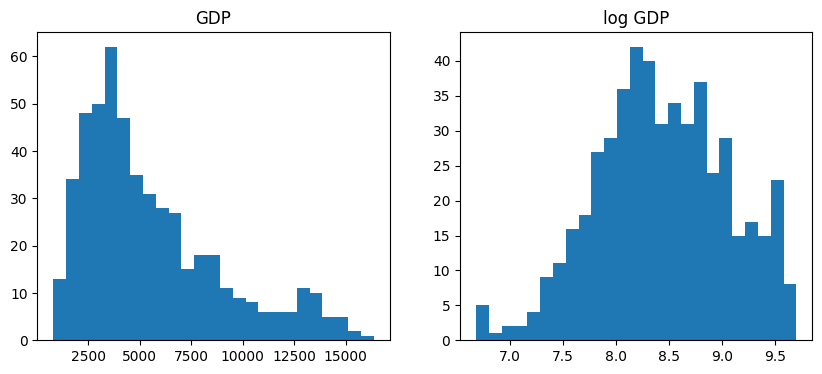

1.08 -0.13


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].hist(df["NY.GDP.PCAP.PP.KD"], bins=25)
ax[0].set_title("GDP")
ax[1].hist(np.log(df["NY.GDP.PCAP.PP.KD"]), bins=25)
ax[1].set_title("log GDP")
plt.savefig("chart2_log_transform.png", dpi=150, bbox_inches="tight")
plt.show()

print(df["NY.GDP.PCAP.PP.KD"].skew().round(2), np.log(df["NY.GDP.PCAP.PP.KD"]).skew().round(2))

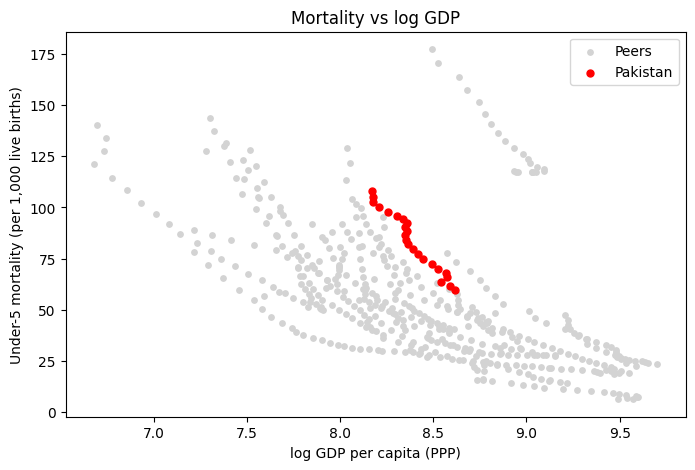

all: -0.57
pakistan: -0.98


In [7]:
d = df.copy()
d["log_gdp"] = np.log(d["NY.GDP.PCAP.PP.KD"])
p = d[d["Country Name"] == "Pakistan"]

plt.figure(figsize=(8, 5))
plt.scatter(d["log_gdp"], d["SH.DYN.MORT"], color="lightgrey", s=15, label="Peers")
plt.scatter(p["log_gdp"], p["SH.DYN.MORT"], color="red", s=25, label="Pakistan")
plt.xlabel("log GDP per capita (PPP)")
plt.ylabel("Under-5 mortality (per 1,000 live births)")
plt.title("Mortality vs log GDP")
plt.legend()
plt.savefig("chart3_mortality_vs_gdp.png", dpi=150, bbox_inches="tight")
plt.show()

print("all:", d["log_gdp"].corr(d["SH.DYN.MORT"]).round(2))
print("pakistan:", p["log_gdp"].corr(p["SH.DYN.MORT"]).round(2))

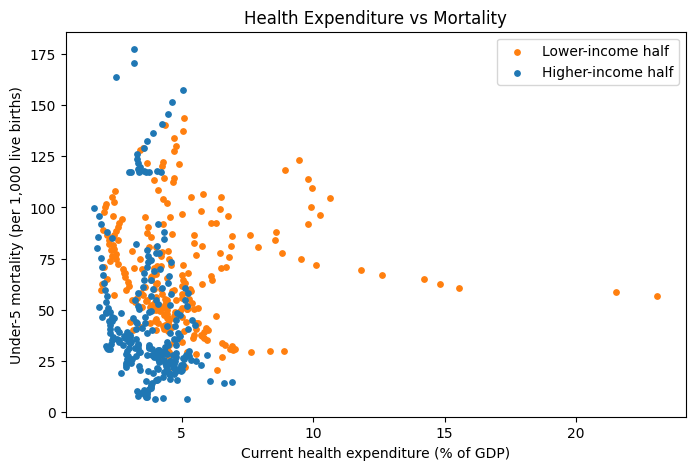

all: 0.03
Higher-income half -0.21 253
Lower-income half -0.04 251
group
Higher-income half    [Bangladesh, Bhutan, Egypt, Arab Rep., Ghana, ...
Lower-income half     [Afghanistan, Cambodia, Ethiopia, Kenya, Myanm...
Name: Country Name, dtype: object


In [10]:
d = d.dropna(subset=["SH.XPD.CHEX.GD.ZS"]).copy()
avg_gdp = d.groupby("Country Name")["NY.GDP.PCAP.PP.KD"].mean()
d["group"] = np.where(d["Country Name"].map(avg_gdp) > avg_gdp.median(), "Higher-income half", "Lower-income half")

plt.figure(figsize=(8, 5))
for g, c in [("Lower-income half", "tab:orange"), ("Higher-income half", "tab:blue")]:
    s = d[d["group"] == g]
    plt.scatter(s["SH.XPD.CHEX.GD.ZS"], s["SH.DYN.MORT"], color=c, s=15, label=g)
plt.xlabel("Current health expenditure (% of GDP)")
plt.ylabel("Under-5 mortality (per 1,000 live births)")
plt.title("Health Expenditure vs Mortality")
plt.legend()
plt.savefig("chart5_confounder.png", dpi=150, bbox_inches="tight")
plt.show()

print("all:", d["SH.XPD.CHEX.GD.ZS"].corr(d["SH.DYN.MORT"]).round(2))
for g, s in d.groupby("group"):
    print(g, s["SH.XPD.CHEX.GD.ZS"].corr(s["SH.DYN.MORT"]).round(2), len(s))
print(d.groupby("group")["Country Name"].unique())